# Photonic priors → a small PyTorch WGAN-GP → peptide sequences

An executable CPU demonstration inspired by **Engdal, Funk, Bacarreza et al.,
Hybrid quantum-classical de novo design of MHC-binding peptides**
([paper](https://doi.org/10.64898/2026.07.09.736951)).

**Run All:** build a fixed MerLin interferometer, sample Dist and Indist Fock events
with Perceval, normalize them, define a small conditional WGAN-GP **in this notebook**,
train both conditions briefly on CPU, and generate/check 9-residue sequences.

The default training data is an explicitly synthetic motif exercise, not measured
HLA ligands. This makes the demonstration self-contained without redistributing
external datasets. A visible setting below selects manually prepared author data
instead. No MHCflurry model is loaded, downloaded or executed in either mode.
The lightweight GAN and its scores are not the production WGAN-GP experiment.

## 1. Environment and a small execution budget

Install `requirements.txt` for CPU or follow the CUDA setup in README and use
`requirements-gpu.txt`. Both include Jupyter and the MHCflurry package; predictor
weights remain separate and are unnecessary here. The notebook always uses CPU.

The live default is 128 events per condition and 1,000 updates of each small GAN.
It uses one thread, fixed seeds and no external downloads. 

In [1]:
import importlib.metadata
import json
import os
import sys
import tempfile
import time
from pathlib import Path

# Support paper-local, repository-root and flat-workspace notebook launches.
start = Path.cwd().resolve()
candidates = [start, start / "pep_q_gan", start / "papers" / "pep_q_gan"]
PAPER_DIR = next((p for p in candidates if (p / "assets/experiment.json").is_file()), None)
if PAPER_DIR is None:
    raise RuntimeError("Open the notebook from pep_q_gan or the reproduction repository root")
REPO_ROOT = next((p for p in PAPER_DIR.parents if (p / "runtime_lib").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("The shared reproduction runtime is required alongside the paper folder")
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(PAPER_DIR.parent))

scratch_root = PAPER_DIR / "outdir" / "notebook_runs"
scratch_root.mkdir(parents=True, exist_ok=True)
WORK_DIR = Path(tempfile.mkdtemp(prefix="walkthrough_", dir=scratch_root))
os.environ["PCVL_PERSISTENT_PATH"] = str(WORK_DIR / "perceval_cache")
(Path(os.environ["PCVL_PERSISTENT_PATH"]) / "logs").mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import exqalibur as xq
import perceval as pc
from IPython import get_ipython
from IPython.display import Markdown, display

from pep_q_gan.lib.circuits import circuit_from_spec, circuit_id, fock_moments, generate_spec, input_state
from pep_q_gan.lib.circuit_visualization import draw_mzi_mesh
from pep_q_gan.lib.data_setup import load_training_data
from pep_q_gan.lib.training import TrainingConfig, gradient_penalty, make_optimizer
from pep_q_gan.lib.distinguishable import sample_distinguishable

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(1)
xq.Config.compute_max_thread_count = 1
xq.Config.use_single_precision = False
torch.manual_seed(42)
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

print("Notebook workspace ready under ignored outdir/notebook_runs.")
from torch import nn
from torch.nn import functional as F
DEMO_STARTED = time.perf_counter()

Notebook workspace ready under ignored outdir/notebook_runs.


In [2]:
DEMO_EVENTS = 128
TRAIN_STEPS = 1000
BATCH_SIZE = 32
HIDDEN_WIDTH = 64
CRITIC_UPDATES = 5
GP_WEIGHT = 1.0
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
WARMUP_STEPS = 100
DATA_SOURCE = "synthetic"  # Explicit choice: "synthetic" or "author".
DATA_ROOT = None          # Set to your manually prepared author-data directory.
SEED = 42
DEVICE = torch.device("cpu")
assert TRAIN_STEPS > 0 and DEMO_EVENTS >= BATCH_SIZE
display(pd.DataFrame([
    {"package": name, "installed": importlib.metadata.version(name)}
    for name in ["merlinquantum", "perceval-quandela", "exqalibur", "torch", "numpy"]
]))
print(f"CPU demo: {DEMO_EVENTS} events/condition; {TRAIN_STEPS} updates/model; data={DATA_SOURCE}.")

,package,installed
0,merlinquantum,0.4.2
1,perceval-quandela,1.3.1
2,exqalibur,1.4.2
3,torch,2.12.1
4,numpy,2.5.4


CPU demo: 128 events/condition; 1000 updates/model; data=synthetic.


## 2. MerLin circuit and a fixed Fock state

We retain the experiment's **32 modes**, **16 photons**, input `[1, 0] * 16` and
one full MerLin MZI entangling mesh. This is a full mesh, not one beam-splitter row.
Optical phases remain fixed; only the small classical networks will be trained.
The circuit factory is shared with the full experiment and is constructed afresh from seed 42 on each run.

The overview below follows the actual compiled circuit, showing occupied/vacuum
inputs and every MZI coupling. Non-optical layout barriers are omitted. One entangling layer
means this entire mesh. Dist and Indist use this same circuit; their photon labels differ in Section 3.

{'modes': 32,
 'photons': 16,
 'layers': 1,
 'trainable_optical_parameters': False,
 'unitarity_max_error': 1.0214052171964643e-14,
 'recipe_id': '7f353a8c4d7866abdee572d726c462a2a052dedf4fe0133a5263929d8c8cbb59'}

{'modes': 32,
 'mzis': 496,
 'coupling_stages': 32,
 'output_phase_shifters': 0,
 'input_photons': 16}

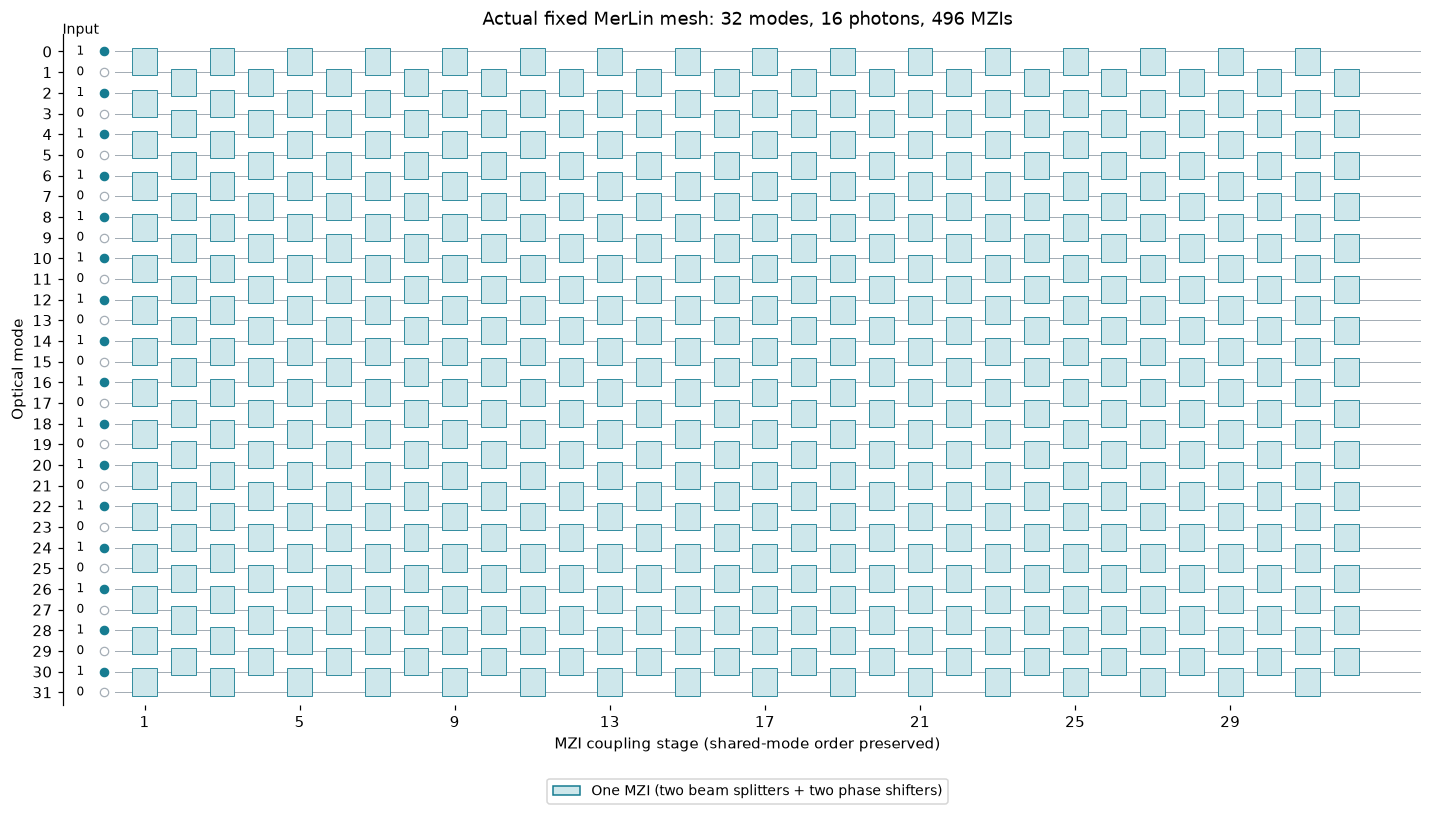

**Inside the first MZI: two beam splitters and two fixed phase shifters**

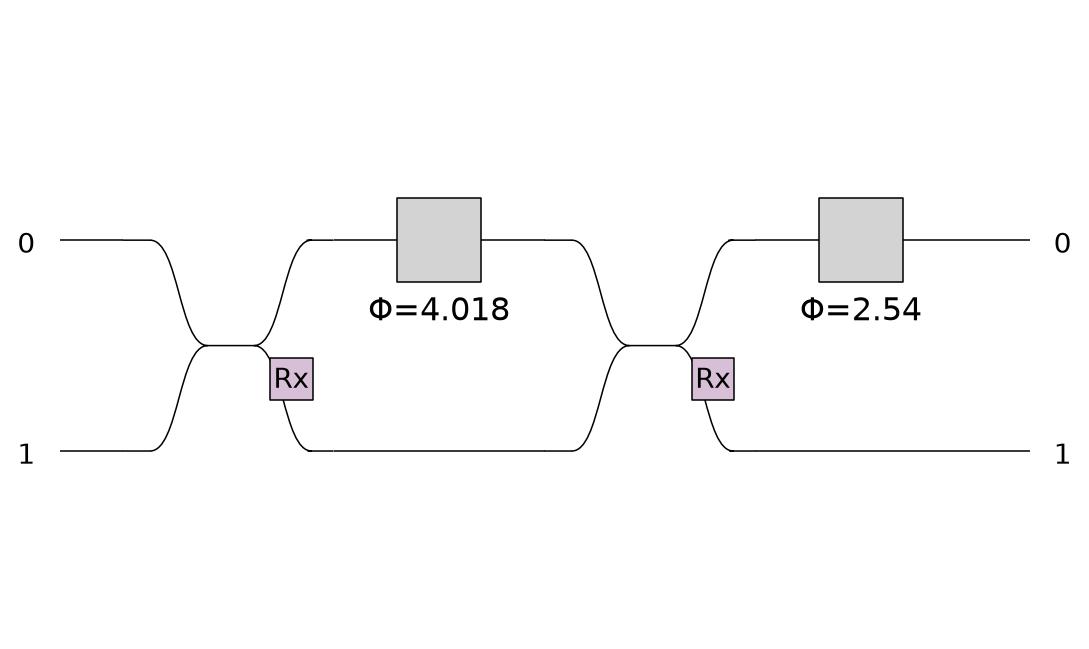

In [3]:
spec = generate_spec(seed=42)
circuit, unitary = circuit_from_spec(spec)
fock_input = input_state(16, 32)
unitarity_error = float(np.max(np.abs(unitary.conj().T @ unitary - np.eye(32))))
assert fock_input == [1, 0] * 16 and unitarity_error < 1e-10
display({"modes": 32, "photons": sum(fock_input), "layers": 1,
         "trainable_optical_parameters": False, "unitarity_max_error": unitarity_error,
         "recipe_id": circuit_id(spec)})
fig, first_mzi, topology = draw_mzi_mesh(circuit, fock_input)
display(topology)
plt.show()

display(Markdown("**Inside the first MZI: two beam splitters and two fixed phase shifters**"))
from perceval.rendering.circuit import SymbSkin
pc.pdisplay(first_mzi, output_format=pc.Format.MPLOT,
            skin=SymbSkin(compact_display=True), precision=1e-3, nsimplify=False)
assert np.allclose(np.asarray(circuit.compute_unitary()), unitary, atol=1e-12, rtol=0)


## 3. Perceval Dist/Indist sampling and normalization

Dist assigns a unique integer label to every photon through public Perceval
`SimulatedComputer.samples`; Indist samples the full untagged Fock input through
`Clifford2017Backend`. Both keep collisions and conserve 16 photons per event.
Their ideal means agree, while covariances and higher-order statistics can differ.

We normalize the sampled photon counts using the analytic mean and standard deviation of each prior: $z_i=(n_i-\mu_i)/\sigma_i$. For each prior, 128 events are sampled and reused during the training.

In [4]:
def sample_events(condition, samples, event_seed):
    """Draw fresh Perceval occupations directly into memory, without a sample file."""
    if condition == "dist":
        counts, _ = sample_distinguishable(circuit, fock_input, samples, event_seed)
    elif condition == "indist":
        pc.random_seed(event_seed)
        backend = pc.Clifford2017Backend()
        backend.set_circuit(circuit)
        backend.set_input_state(pc.BasicState(fock_input))
        counts = np.asarray([list(event) for event in backend.samples(samples)], dtype=np.uint16)
    else:
        raise ValueError("Choose 'dist' or 'indist'")
    assert counts.shape == (samples, 32) and np.all(counts.sum(axis=1) == 16)
    return counts


live_counts = {condition: sample_events(condition, DEMO_EVENTS, event_seed=20261022)
               for condition in ["dist", "indist"]}
display(pd.DataFrame([
    {"condition": condition, "fresh_training_events": len(counts),
     "photons_in_every_event": 16, "collisions_retained": True, "loaded_from_file": False}
    for condition, counts in live_counts.items()
]))

,condition,fresh_training_events,photons_in_every_event,collisions_retained,loaded_from_file
0,dist,128,16,True,False
1,indist,128,16,True,False


{'latent_shape': [4, 32],
 'dtype': 'torch.float32',
 'analytic_means_equal': True,
 'loaded_from_file': False}

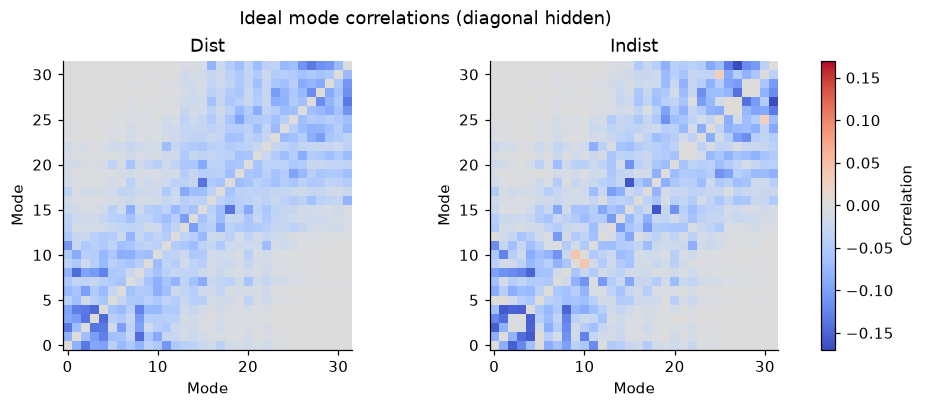

In [5]:
moments = {condition: fock_moments(unitary, fock_input, condition) for condition in ["dist", "indist"]}
assert np.allclose(moments["dist"][0], moments["indist"][0], atol=1e-12, rtol=0)
def normalize_events(counts, condition):
    """Apply analytic moments to fresh event arrays and create float32 latents."""
    mean, covariance = moments[condition]
    std = np.sqrt(np.diag(covariance))
    assert np.all(std > 0)
    values = (counts.astype(np.float64) - mean) / std
    return torch.from_numpy(values.astype(np.float32))


live_latents = {condition: normalize_events(counts, condition)
                for condition, counts in live_counts.items()}


def draw_latents(condition, batch_size):
    """Select a minibatch from the fresh in-memory training events."""
    values = live_latents[condition]
    return values[torch.randint(len(values), (batch_size,))]


z = draw_latents("indist", 4)
assert z.shape == (4, 32) and z.dtype == torch.float32 and torch.isfinite(z).all()
display({"latent_shape": list(z.shape), "dtype": str(z.dtype), "analytic_means_equal": True,
         "loaded_from_file": False})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
correlations = {}
for condition, (_, cov) in moments.items():
    std = np.sqrt(np.diag(cov))
    correlations[condition] = cov / np.outer(std, std)
    np.fill_diagonal(correlations[condition], 0)
limit = max(float(np.abs(value).max()) for value in correlations.values())
for ax, condition in zip(axes, ["dist", "indist"]):
    image = ax.imshow(correlations[condition], origin="lower", cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.set(xlabel="Mode", ylabel="Mode", title=condition.title())
fig.suptitle("Ideal mode correlations (diagonal hidden)")
fig.colorbar(image, ax=axes.tolist(), label="Correlation")
plt.show()

## 4. A small, explicit sequence-training task

**Default `DATA_SOURCE="synthetic"`:** generate 512 artificial canonical 9-mers
with two equally sized conditions. `Synthetic-A` favors L at P2 and V at P9;
`Synthetic-B` favors F at P2 and K at P9 (80% motif probability per anchor).
**A/B are artificial motif classes, unrelated to HLA-A/HLA-B loci or specific HLA alleles.**
Other positions are uniform. These are invented teaching motifs, **not HLA names,
binding labels, experimental observations or a biological benchmark**.

**Optional `DATA_SOURCE="author"`:** manually prepare `HLA_pos9mers.txt` using
[README](README.md#download-the-two-required-training-inputs), set `DATA_ROOT`,
and restart Run All. The cell selects the two most represented HLA among positive
canonical 9-mers and uses up to 256 rows per HLA. This toy model uses a categorical
condition embedding rather than the full model's 34-residue HLA pseudosequence;
it cannot condition on unseen HLA. Filtering is local to this teaching demo and
does not change the archived production dataset or performance figures.

In [6]:
ALPHABET = "ACDEFGHIKLMNPQRSTVWY"
aa_to_id = {aa: i for i, aa in enumerate(ALPHABET)}
data_rng = np.random.default_rng(SEED)
if DATA_SOURCE == "synthetic":
    condition_names = ["Synthetic-A", "Synthetic-B"]
    anchors = [("L", "V"), ("F", "K")]
    real_ids = torch.from_numpy(data_rng.integers(0, 20, size=(512, 9))).long()
    real_labels = torch.arange(512) // 256
    for label, (p2, p9) in enumerate(anchors):
        rows = np.arange(label * 256, (label + 1) * 256)
        for position, residue in [(1, p2), (8, p9)]:
            selected = rows[data_rng.random(len(rows)) < 0.8]
            real_ids[torch.as_tensor(selected), position] = aa_to_id[residue]
elif DATA_SOURCE == "author":
    if DATA_ROOT is None:
        raise ValueError("Set DATA_ROOT; author data is never downloaded or substituted automatically")
    records = load_training_data(Path(DATA_ROOT) / "HLA_pos9mers.txt")
    eligible = [r for r in records if r.label == 1 and len(r.peptide) == 9 and set(r.peptide) <= set(ALPHABET)]
    counts = pd.Series([r.hla for r in eligible]).value_counts()
    condition_names = sorted(counts.index, key=lambda h: (-counts[h], h))[:2]
    if len(condition_names) != 2:
        raise ValueError("The author demo needs two HLA with canonical positive 9-mers")
    selected_rows, selected_labels = [], []
    for label, hla in enumerate(condition_names):
        peptides = [r.peptide for r in eligible if r.hla == hla]
        chosen = data_rng.permutation(len(peptides))[:256]
        selected_rows.extend([[aa_to_id[aa] for aa in peptides[i]] for i in chosen])
        selected_labels.extend([label] * len(chosen))
    real_ids = torch.tensor(selected_rows, dtype=torch.long)
    real_labels = torch.tensor(selected_labels, dtype=torch.long)
else:
    raise ValueError("Choose DATA_SOURCE='synthetic' or 'author'")
real_onehot = F.one_hot(real_ids, num_classes=20).float()
assert real_onehot.shape[1:] == (9, 20) and set(real_labels.tolist()) == {0, 1}
display(pd.DataFrame({"condition": condition_names,
                      "label_type": ["Synthetic motif (not HLA)"] * 2 if DATA_SOURCE == "synthetic" else ["HLA allele"] * 2,
                      "training_rows": [(real_labels == i).sum().item() for i in range(2)]}))
print("Data source:", DATA_SOURCE, "| This is a learning-interface demonstration, not a binding benchmark.")

,condition,label_type,training_rows
0,Synthetic-A,Synthetic motif (not HLA),256
1,Synthetic-B,Synthetic motif (not HLA),256


Data source: synthetic | This is a learning-interface demonstration, not a binding benchmark.


## 5. Define the lightweight conditional WGAN-GP here

The generator maps a 32-coordinate photonic latent and an 8-coordinate learned
condition embedding through two 64-wide MLP layers to **9 × 20 logits**. The
critic is a small MLP with an unrestricted real-valued output, without a sigmoid.

The training objective matches the full experiment:

$$L_D=\mathbb{E}[D(G(z,c),c)]-\mathbb{E}[D(x,c)]
+\lambda\,\mathbb{E}[(\|\nabla_{\hat{x}}D(\hat{x},c)\|_2-1)^2],
\qquad L_G=-\mathbb{E}[D(G(z,c),c)].$$

As in the full trainer, generated logits become softmax probabilities for critic
training; real sequences are one-hot tensors. There is no BCE or Gumbel-softmax.
We use **five critic updates per generator update**, **GP weight 1**, AdamW
(`lr=1e-4`, weight decay `1e-4`, betas `(0.5, 0.999)`) and 100-step linear warmup.
The gradient-penalty and optimizer helpers are imported directly from the full
training implementation. The small model and short loop remain visible below.

The demonstration still uses a smaller MLP, a 20-symbol alphabet and categorical
conditions; the full model uses its larger architecture and HLA pseudosequences.
Synthetic A/B are artificial motif classes, not biological HLA labels.

In [7]:
class LiteGenerator(nn.Module):
    """Generate nine categorical residues from a photonic latent and condition ID."""

    def __init__(self, hidden=64):
        super().__init__()
        self.embedding = nn.Embedding(2, 8)
        self.norm = nn.RMSNorm(32, eps=1e-6)
        self.net = nn.Sequential(nn.Linear(40, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 9 * 20))

    def forward(self, latent, labels):
        features = torch.cat([self.norm(latent), self.embedding(labels)], dim=-1)
        return self.net(features).reshape(-1, 9, 20)


class LiteCritic(nn.Module):
    """Return an unbounded critic score for a peptide and condition ID."""

    def __init__(self, hidden=64):
        super().__init__()
        self.embedding = nn.Embedding(2, 8)
        self.net = nn.Sequential(nn.Linear(9 * 20 + 8, hidden), nn.LeakyReLU(0.2),
                                 nn.Linear(hidden, hidden), nn.LeakyReLU(0.2), nn.Linear(hidden, 1))

    def forward(self, peptide, labels):
        return self.net(torch.cat([peptide.flatten(1), self.embedding(labels)], dim=-1)).squeeze(-1)


torch.manual_seed(SEED)
example_g, example_d = LiteGenerator(HIDDEN_WIDTH), LiteCritic(HIDDEN_WIDTH)
display({"generator_parameters": sum(p.numel() for p in example_g.parameters()),
         "critic_parameters": sum(p.numel() for p in example_d.parameters()),
         "device": str(DEVICE), "hidden_width": HIDDEN_WIDTH, "output_symbols": 20})
del example_g, example_d

{'generator_parameters': 18532,
 'critic_parameters': 16337,
 'device': 'cpu',
 'hidden_width': 64,
 'output_symbols': 20}

## 6. Brief CPU WGAN-GP training

Train a separate small model for Dist and Indist with fixed seed 42. Every update
uses normalized events sampled earlier in this run. Only the prior changes between
conditions. Each generator update follows five critic updates with active gradient
penalty. The first update has zero learning rate during the shared warmup schedule.

We record critic total loss, Wasserstein term, gradient penalty and generator loss
separately, and verify that the total equals the Wasserstein term plus weighted GP.
Wasserstein critic scores have no fixed zero point: generator loss alone does not
certify convergence. Inspect the motif table and generated-sequence diversity too.

,prior,generator_updates,critic_updates,gp_weight,seconds,generator_change_l1,critic_change_l1,mean_gradient_penalty,finite_losses
0,dist,1000,5000,1.0,16.036099,693.945729,620.758133,0.384383,True
1,indist,1000,5000,1.0,15.497193,666.502891,622.972947,0.384377,True


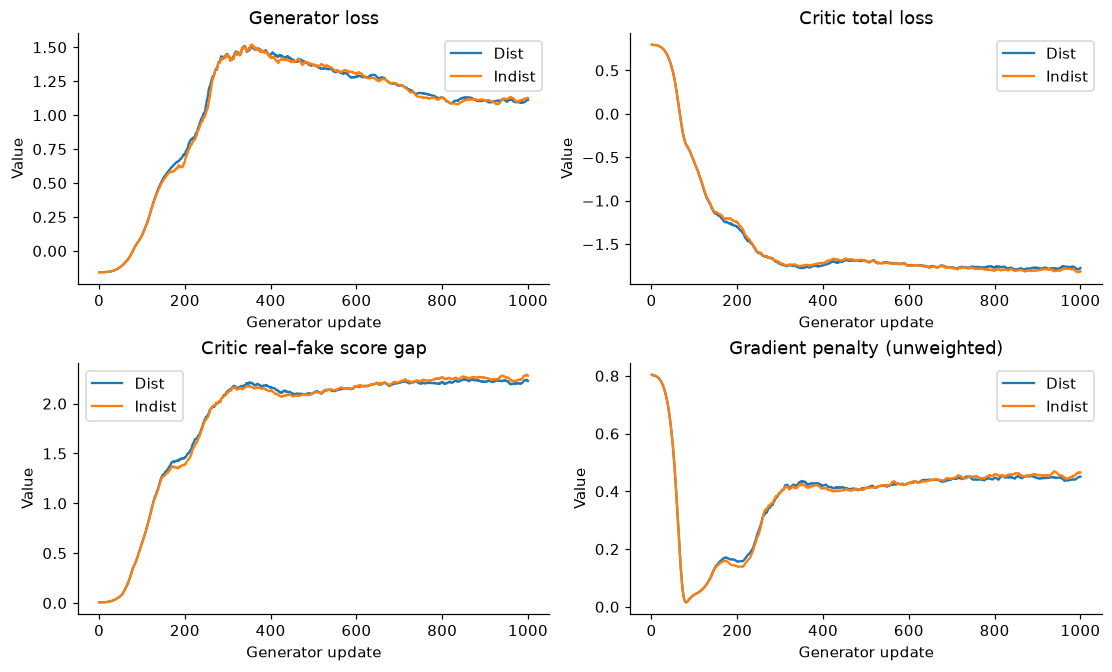

In [8]:
def train_lite(condition):
    """Train the small conditional WGAN-GP with the full experiment's objective."""
    torch.manual_seed(SEED)
    generator = LiteGenerator(HIDDEN_WIDTH).to(DEVICE)
    critic = LiteCritic(HIDDEN_WIDTH).to(DEVICE)
    cfg = TrainingConfig(prior=condition, seed=SEED, device=str(DEVICE),
        batch_size=BATCH_SIZE, max_steps=TRAIN_STEPS, rng_mode="global_device",
        learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
        discriminator_iterations=CRITIC_UPDATES, gradient_penalty=GP_WEIGHT,
        warmup_steps=WARMUP_STEPS)
    opt_g = make_optimizer(generator, cfg)
    opt_d = make_optimizer(critic, cfg)
    before_g = [p.detach().clone() for p in generator.parameters()]
    before_d = [p.detach().clone() for p in critic.parameters()]
    history = []
    started = time.perf_counter()
    for step in range(TRAIN_STEPS):
        lr = min(step / cfg.warmup_steps, 1.0) * cfg.learning_rate if cfg.warmup_steps else cfg.learning_rate
        for optimizer in [opt_g, opt_d]:
            for group in optimizer.param_groups:
                group["lr"] = lr
        critic.requires_grad_(True)
        critic_metrics = []
        for _ in range(cfg.discriminator_iterations):
            idx = torch.randint(len(real_ids), (BATCH_SIZE,))
            labels = real_labels[idx].to(DEVICE)
            real = real_onehot[idx].to(DEVICE)
            with torch.no_grad():
                fake = generator(draw_latents(condition, BATCH_SIZE).to(DEVICE), labels).softmax(-1)
            opt_d.zero_grad(set_to_none=True)
            wasserstein = critic(fake, labels).mean() - critic(real, labels).mean()
            epsilon = torch.rand(BATCH_SIZE, 1, 1, device=DEVICE)
            gp = gradient_penalty(critic, real, fake, labels, epsilon)
            d_loss = wasserstein + cfg.gradient_penalty * gp
            assert torch.isfinite(d_loss) and torch.isfinite(gp)
            d_loss.backward()
            assert all(torch.isfinite(p.grad).all() for p in critic.parameters() if p.grad is not None)
            opt_d.step()
            critic_metrics.append([d_loss.item(), wasserstein.item(), gp.item()])

        critic.requires_grad_(False)
        idx = torch.randint(len(real_ids), (BATCH_SIZE,))
        labels = real_labels[idx].to(DEVICE)
        opt_g.zero_grad(set_to_none=True)
        fake = generator(draw_latents(condition, BATCH_SIZE).to(DEVICE), labels).softmax(-1)
        g_loss = -critic(fake, labels).mean()
        assert torch.isfinite(g_loss)
        g_loss.backward()
        assert all(torch.isfinite(p.grad).all() for p in generator.parameters() if p.grad is not None)
        opt_g.step()
        d_value, w_value, gp_value = np.mean(critic_metrics, axis=0)
        assert abs(d_value - w_value - cfg.gradient_penalty * gp_value) < 1e-5
        history.append({"prior": condition, "step": step + 1, "lr": lr,
            "g_loss": g_loss.item(), "d_loss": d_value, "wasserstein_loss": w_value,
            "wasserstein_gap": -w_value, "gradient_penalty": gp_value})

    change_g = sum((p.detach() - b).abs().sum().item() for p, b in zip(generator.parameters(), before_g))
    change_d = sum((p.detach() - b).abs().sum().item() for p, b in zip(critic.parameters(), before_d))
    assert change_g > 0 and change_d > 0
    assert all(torch.isfinite(p).all() for p in list(generator.parameters()) + list(critic.parameters()))
    return generator.eval(), history, {"prior": condition, "generator_updates": TRAIN_STEPS,
        "critic_updates": TRAIN_STEPS * cfg.discriminator_iterations, "gp_weight": cfg.gradient_penalty,
        "seconds": time.perf_counter() - started, "generator_change_l1": change_g,
        "critic_change_l1": change_d, "mean_gradient_penalty": float(np.mean([h["gradient_penalty"] for h in history])),
        "finite_losses": True}


models, histories, training_checks = {}, [], []
for condition in ["dist", "indist"]:
    models[condition], history, check = train_lite(condition)
    histories.extend(history)
    training_checks.append(check)
history_table = pd.DataFrame(histories)
history_table.to_csv(WORK_DIR / "lite_losses.csv", index=False)
display(pd.DataFrame(training_checks))
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
panels = [("g_loss", "Generator loss"), ("d_loss", "Critic total loss"),
          ("wasserstein_gap", "Critic real–fake score gap"), ("gradient_penalty", "Gradient penalty (unweighted)")]
for condition, group in history_table.groupby("prior"):
    for ax, (key, title) in zip(axes.flat, panels):
        ax.plot(group.step, group[key].rolling(10, min_periods=1).mean(), label=condition.title())
        ax.set(xlabel="Generator update", ylabel="Value", title=title)
        ax.legend()
plt.show()

## 7. Generate and inspect peptide sequences

Draw from each learned categorical output with temperature 1.0, conditioned on
each training label. All generated attempts are kept. We report length/alphabet
validity, duplicate rate, exact training-set matches and P2/P9 residues.

Nine positions and the canonical 20-residue alphabet are enforced by this toy
architecture, so validity is **not evidence of learned biology**. Exact matches
may indicate memorization. Synthetic motif recovery is an illustration, not HLA
binding, presentation, novelty or experimental validation. Generation uses freshly sampled Perceval events with a separate event seed.
They are independent draws and can still repeat an earlier occupation pattern.

For synthetic data, the table compares training motif frequencies, model
probabilities averaged over fresh generation latents, and frequencies in the
16 generated sequences per group. These small sampled counts can fluctuate;
matching the synthetic motif is not a test of HLA binding.

In [9]:
ATTEMPTS_PER_CONDITION = 16
generated_rows = []
fresh_generation_counts = {}
motif_rows = []
for condition, generator in models.items():
    torch.manual_seed(12345)
    fresh_counts = sample_events(condition, 2 * ATTEMPTS_PER_CONDITION, event_seed=20261023)
    fresh_generation_counts[condition] = len(fresh_counts)
    generation_latents = normalize_events(fresh_counts, condition)
    for label, name in enumerate(condition_names):
        start = label * ATTEMPTS_PER_CONDITION
        latent = generation_latents[start:start + ATTEMPTS_PER_CONDITION].to(DEVICE)
        labels = torch.full((ATTEMPTS_PER_CONDITION,), label, dtype=torch.long, device=DEVICE)
        with torch.inference_mode():
            logits = generator(latent, labels)
            tokens = torch.multinomial(logits.softmax(-1).reshape(-1, 20), 1).reshape(-1, 9)
        if DATA_SOURCE == "synthetic":
            target_ids = real_ids[real_labels == label]
            probabilities = logits.softmax(-1)
            for position, residue in [(1, anchors[label][0]), (8, anchors[label][1])]:
                residue_id = aa_to_id[residue]
                motif_rows.append({"prior": condition, "synthetic_condition": name,
                    "position": f"P{position + 1}", "target_residue": residue,
                    "training_frequency_pct": 100 * (target_ids[:, position] == residue_id).float().mean().item(),
                    "model_probability_pct": 100 * probabilities[:, position, residue_id].mean().item(),
                    "generated_frequency_pct": 100 * (tokens[:, position] == residue_id).float().mean().item()})
        training_sequences = {"".join(ALPHABET[i] for i in row) for row in real_ids[real_labels == label].tolist()}
        for attempt, row in enumerate(tokens.tolist(), 1):
            peptide = "".join(ALPHABET[i] for i in row)
            generated_rows.append({"prior": condition, "condition": name, "attempt": attempt,
                "peptide": peptide, "length": len(peptide), "canonical_9mer": len(peptide) == 9 and set(peptide) <= set(ALPHABET),
                "P2": peptide[1], "P9": peptide[8], "in_demo_training": peptide in training_sequences})
generated = pd.DataFrame(generated_rows)
assert len(generated) == 2 * 2 * ATTEMPTS_PER_CONDITION and generated.canonical_9mer.all()
generated.to_csv(WORK_DIR / "lite_generated_peptides.csv", index=False)
display(generated.groupby(["prior", "condition"], sort=False).head(4).reset_index(drop=True))
sequence_checks = generated.groupby(["prior", "condition"]).agg(
    attempts=("peptide", "size"), unique_sequences=("peptide", "nunique"),
    canonical_rate=("canonical_9mer", "mean"), training_match_rate=("in_demo_training", "mean"))
sequence_checks["duplicate_rate"] = 1 - sequence_checks.unique_sequences / sequence_checks.attempts
display(sequence_checks)
if motif_rows:
    display(pd.DataFrame(motif_rows).round(1))
    print("Model probabilities average over the fresh generation latents; generated rates use only 16 sequences per group.")
demo_summary = {"data_source": DATA_SOURCE, "device": str(DEVICE), "events_per_prior": DEMO_EVENTS,
    "fresh_generation_events": fresh_generation_counts, "sample_files_loaded": False,
    "sample_files_written": False, "updates_per_model": TRAIN_STEPS, "objective": "WGAN-GP",
    "critic_updates_per_generator": CRITIC_UPDATES, "gp_weight": GP_WEIGHT, "training_rows": len(real_ids), "conditions": condition_names,
    "training_checks": training_checks, "generated_attempts": len(generated), "all_canonical_9mers": True,
    "mhcflurry_run": False, "predictor_weights_downloaded": False}
(WORK_DIR / "lite_summary.json").write_text(json.dumps(demo_summary, indent=2))
print("Live demo complete. Saved losses, every generated attempt and summary under ignored notebook scratch.")

,prior,condition,attempt,peptide,length,canonical_9mer,P2,P9,in_demo_training
0,dist,Synthetic-A,1,YLKYHRLWV,9,True,L,V,False
1,dist,Synthetic-A,2,CLFVKVVFV,9,True,L,V,False
2,dist,Synthetic-A,3,GLRAELAPV,9,True,L,V,False
3,dist,Synthetic-A,4,LLLGYHFDV,9,True,L,V,False
4,dist,Synthetic-B,1,KFTFMFTCK,9,True,F,K,False
5,dist,Synthetic-B,2,EFTIMRYEK,9,True,F,K,False
6,dist,Synthetic-B,3,TFTRDMYDK,9,True,F,K,False
7,dist,Synthetic-B,4,TFRTIGCEK,9,True,F,K,False
8,indist,Synthetic-A,1,YLKRHRLWV,9,True,L,V,False
9,indist,Synthetic-A,2,HLNVKVFFV,9,True,L,V,False


attempts  unique_sequences  canonical_rate  \
prior  condition                                                 
dist   Synthetic-A        16                16             1.0   
       Synthetic-B        16                16             1.0   
indist Synthetic-A        16                16             1.0   
       Synthetic-B        16                16             1.0   

                    training_match_rate  duplicate_rate  
prior  condition                                         
dist   Synthetic-A                  0.0             0.0  
       Synthetic-B                  0.0             0.0  
indist Synthetic-A                  0.0             0.0  
       Synthetic-B                  0.0             0.0

,prior,synthetic_condition,position,target_residue,training_frequency_pct,model_probability_pct,generated_frequency_pct
0,dist,Synthetic-A,P2,L,83.6,87.6,93.8
1,dist,Synthetic-A,P9,V,77.7,88.1,93.8
2,dist,Synthetic-B,P2,F,84.4,81.9,93.8
3,dist,Synthetic-B,P9,K,81.6,78.3,68.8
4,indist,Synthetic-A,P2,L,83.6,87.6,93.8
5,indist,Synthetic-A,P9,V,77.7,85.8,93.8
6,indist,Synthetic-B,P2,F,84.4,73.2,68.8
7,indist,Synthetic-B,P9,K,81.6,69.5,56.2


Model probabilities average over the fresh generation latents; generated rates use only 16 sequences per group.
Live demo complete. Saved losses, every generated attempt and summary under ignored notebook scratch.


## 8. What this notebook demonstrates

- MerLin builds a fixed circuit; Perceval samples fresh Dist/Indist Fock events.
- Normalized events drive short CPU training of the small PyTorch GANs defined here.
- The trained models generate 9-mers, with motif frequencies and duplicates inspected.

Synthetic A/B are artificial motif conditions, not HLA alleles. This demonstration
does not assess binding or rank priors; MHCflurry is not executed.

For the full experiment, final figures and data preparation, see [README](README.md)
and [data sources](DATA_SOURCES.md).
